In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
from sklearn.metrics import r2_score

from functions.load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from functions.plotting import savefig, paper_plot
#from functions.statistics_functions import chi_squared

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
data, var = load_data_and_var()

In [4]:
nfws_full=generate_nfws_from_combined_dataset_werr(data, var)

In [5]:
Ms = [nfw.M500 for nfw in nfws_full]

In [7]:
iqbal_heating = [nfw.total_heating_rate(0.001*nfw.R500, 1*nfw.R500, 0.1*nfw.R500, Linj = None,n=50) for nfw in nfws_full]

In [32]:
cooling = [nfw.total_cooling_rate(0.001*nfw.R500, 1*nfw.R500, n=50) for nfw in nfws_full]

In [ ]:
# EKS replace this with something more accurate
def M200(nfw):
    return 1.25 * nfw.M500

In [27]:
nfws_full[0].L500

In [21]:
def Donahue_heating(nfw):
    return 2e44 * (M200(nfw)/(1e14))**(5./3)

In [22]:
donahue_heating = [Donahue_heating(nfw) for nfw in nfws_full]

In [30]:
q=0.1
mu=0.59
cca_rate = [q*mu*const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value * nfw.L500*1e44/(3./2 * nfw.T500) for nfw in nfws_full]

In [61]:
bondi_rate = [nfw.total_gaspari_agn_heating_rate() for nfw in nfws_full]
bondi_rate

In [55]:
((const.G * u.Msun/const.c**2)**2).to(u.Mpc**2)

<Quantity 2.29002048e-39 Mpc2>

In [56]:
nfws_full[0].get_Mbh()

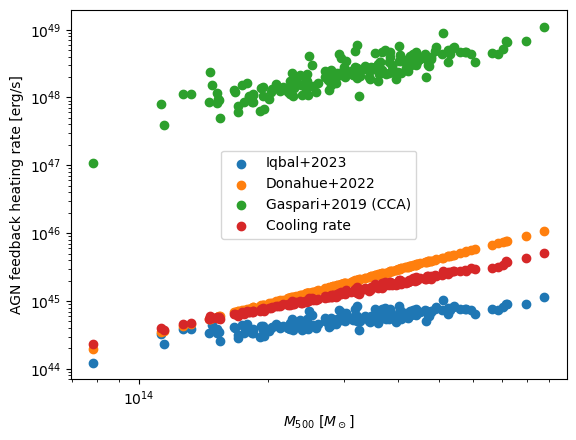

In [63]:
plt.scatter(Ms, iqbal_heating, label = "Iqbal+2023")
plt.scatter(Ms, donahue_heating, label = "Donahue+2022")
plt.scatter(Ms, cca_rate, label = "Gaspari+2019 (CCA)")
#plt.scatter(Ms, bondi_rate, label = "Gaspari+2019 (Bondi)")
plt.scatter(Ms, cooling, label = "Cooling rate")
plt.xscale('log')
plt.yscale('log')

plt.xlabel(r'$M_{500}$ [$M_\odot$]')
plt.ylabel(r'AGN feedback heating rate [erg/s]')
plt.legend()